# Case 1: Screening a Consumer Auto-Loan Pricing Model

**Your role:** analyst candidate on a consumer-finance team  
**Decision maker:** head of auto-loan pricing  
**Data:** `case01_auto_loan_apr_lab.csv`, 603 raw application records

## Brief

The current rule of thumb lowers the quoted APR by 1 percentage point for every 25 points of FICO. The pricing head suspects that this overstates how much APR should move when FICO rises. You receive a raw export with missing values, duplicate application IDs, invalid codes, one obvious APR extraction error, and one economically unusual but potentially legitimate loan. Management wants a defensible descriptive model, not a causal claim about changing a person's score.

**Management question:** How strongly is an applicant's credit score associated with the APR quoted by the lender, and is the relationship useful as a first-pass pricing screen?

## Data dictionary

| Variable | Units or type | Meaning |
|---|---|---|
| `application_id` | Identifier | Unique application record. Duplicates are possible in the raw export. |
| `fico_score` | Points | Credit score. The valid range is 300 to 850; values outside it are invalid codes. Some values are missing. |
| `loan_amount_usd` | US dollars | Requested principal. Available for descriptive checks but not part of the baseline model. |
| `apr_pct` | Percentage points | Quoted annual percentage rate. Values above 36 are extraction errors. Some values are missing. |
| `source_batch` | Category | Extraction batch A, B, or C. |

## Submission

- Before you submit, restart the kernel and run all cells. The notebook must run from top to bottom without errors.
- Submit the notebook twice: the .ipynb file and a PDF export with all code and output readable.

In [1]:
# Starter code: run this cell first and do not edit it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# The raw export, exactly as received. Leave raw unchanged and build your analysis sample from it.
raw = pd.read_csv('case01_auto_loan_apr_lab.csv')
raw.head()

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
0,AL100000,644.0,14080.52,8.633,C
1,AL100001,618.0,16914.08,10.524,C
2,AL100002,721.0,33785.22,5.614,C
3,AL100003,728.0,18802.21,8.626,A
4,AL100004,700.0,15159.19,7.118,B


## Stage 1. Frame the business question

State the decision the model will inform. Separate a descriptive pricing relationship from a causal effect of credit score.

**Output:** a two-sentence estimand statement.

This model will inform the recommended adjustment in APR percentage according to applicant's FICO score.
Higher FICO score would result in lower annual loan interest rate (APR percentage).

## Stage 2. Audit the raw file

Check for duplicate IDs, missing values, and values outside the valid ranges in the data dictionary. Apply the rules in this order: duplicate IDs, missing values, FICO range, APR range. When an `application_id` appears more than once, keep its first record and remove the later ones. Record how many records each rule removes. Remove a record that breaks a rule; do not correct its value. Do not remove a record just because its values look unusual. Store your analysis sample as `df`.

**Output:** a cleaning log and the final sample size.

In [2]:
#1st step : check the data description for general value screening
print(raw.describe())
print(raw.shape)

       fico_score  loan_amount_usd     apr_pct
count  598.000000       603.000000  599.000000
mean   688.993311     26504.044411    8.517753
std     53.778813     11259.174112    3.817821
min    528.000000      5521.830000    2.770000
25%    651.000000     18451.135000    6.820000
50%    691.000000     24745.730000    8.404000
75%    725.000000     32201.840000    9.871500
max    999.000000     75000.000000   86.000000
(603, 5)


In [3]:
#difference in count for each columns indicates there are missing values. 
#in addition, it is mentioned that fico > 850 and apr_pct > 36 is extraction error

In [4]:
#2nd step : check duplicate
raw.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
598    False
599    False
600     True
601     True
602     True
Length: 603, dtype: bool

In [5]:
raw[raw.duplicated()]

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
600,AL100041,710.0,28277.26,8.450,A
601,AL100218,624.0,33787.29,10.318,A
602,AL100503,749.0,18786.75,5.645,A


In [6]:
#clean the duplicates
dupe_clean = raw.drop_duplicates()
dupe_clean.shape

(600, 5)

In [7]:
#step 3. check missing values
dupe_clean.isna().sum()

application_id     0
fico_score         5
loan_amount_usd    0
apr_pct            4
source_batch       0
dtype: int64

In [8]:
df_filled = dupe_clean.dropna()
print(df_filled.shape)
df_filled.isna().sum()

(591, 5)


application_id     0
fico_score         0
loan_amount_usd    0
apr_pct            0
source_batch       0
dtype: int64

In [9]:
#step 4. check FICO values which not in valid range
df_filled[df_filled["fico_score"] >= 850]

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
301,AL100301,999.0,32728.72,5.892,B
517,AL100517,999.0,15879.04,6.798,A


In [10]:
#remove rows with invalid value
df_cleaned_fico = df_filled[df_filled["fico_score"] <= 850]
df_cleaned_fico.describe()

,fico_score,loan_amount_usd,apr_pct
count,589.000000,589.000000,589.000000
mean,687.780985,26562.759796,8.524857
std,50.857155,11312.473178,3.841051
min,528.000000,5521.830000,2.770000
25%,651.000000,18439.810000,6.834000
50%,691.000000,24835.020000,8.404000
75%,725.000000,32286.540000,9.870000
max,835.000000,75000.000000,86.000000


In [11]:
#step 5. check apr_pct values which not in valid range
df_cleaned_fico[df_cleaned_fico["apr_pct"] >= 36]

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
444,AL100444,681.0,25409.88,86.0,B


In [12]:
#remove rows with invalid value
df_clean = df_cleaned_fico[df_cleaned_fico["apr_pct"] <= 36]
print(df_clean.describe())
print(df_clean.shape)

       fico_score  loan_amount_usd     apr_pct
count  588.000000       588.000000  588.000000
mean   687.792517     26564.720476    8.393097
std     50.899686     11322.004751    2.129758
min    528.000000      5521.830000    2.770000
25%    651.000000     18424.035000    6.830750
50%    691.000000     24790.375000    8.398000
75%    725.000000     32294.860000    9.866250
max    835.000000     75000.000000   21.374000
(588, 5)


## Stage 3. Characterize the data

Report summary statistics for your analysis sample and a scatterplot of APR against FICO.

**Output:** one table and one figure.

In [13]:
print("Statistics Summary")
df_clean.describe()

Statistics Summary


,fico_score,loan_amount_usd,apr_pct
count,588.000000,588.000000,588.000000
mean,687.792517,26564.720476,8.393097
std,50.899686,11322.004751,2.129758
min,528.000000,5521.830000,2.770000
25%,651.000000,18424.035000,6.830750
50%,691.000000,24790.375000,8.398000
75%,725.000000,32294.860000,9.866250
max,835.000000,75000.000000,21.374000


Text(0.5, 1.0, 'Approved annual interest rate based on applicant FICO score')

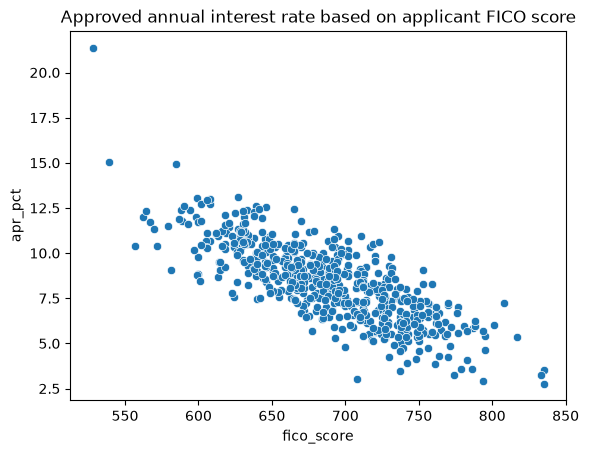

In [14]:
sns.scatterplot(df_clean, x = 'fico_score', y = 'apr_pct')
plt.title('Approved annual interest rate based on applicant FICO score')

## Stage 4. Specify the model

The simple regression model is $y_i = \beta_0 + \beta_1 x_i + u_i$. Write it for this case: say which variable is $y$ and which is $x$, and why. Define the units of $\beta_1$ and predict its sign before estimating.

**Output:** a model statement.

In [15]:
#answer

$y_i = \beta_0 + \beta_1 x_i + u_i$
where y (dependent variable) is apr_pct (the approved annual interest rate),
and x (independent variable) is fico score.

## Stage 5. Estimate the baseline

Estimate the model by OLS on your analysis sample and store the fitted model as `fit`. Report n, the intercept, the slope, the slope's standard error and 95% confidence interval, R-squared, and the residual RMSE, the square root of the mean squared residual.

**Output:** a compact regression table.

In [16]:
fit = smf.ols('apr_pct ~ fico_score', data=df_clean).fit()
fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                apr_pct   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     966.0
Date:                Tue, 13 Oct 2026   Prob (F-statistic):          4.80e-126
Time:                        14:03:21   Log-Likelihood:                -992.01
No. Observations:                 588   AIC:                             1988.
Df Residuals:                     586   BIC:                             1997.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     31.0979      0.733     42.454      0.000      29.659      32.537
fico_score    -0.0330      0.001    -31.081      0.000      -0.035      -0.031
==============================================================================
Omnibus:                       35.902   Durbin-Watson:                   2.088
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               83.327
Skew:                           0.321   Prob(JB):                     8.05e-19
Kurtosis:                       4.729   Cond. No.                     9.35e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.35e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [17]:
fit.params

Intercept     31.097860
fico_score    -0.033011
dtype: float64

## Stage 6. Check the assumptions relevant at this point

Answer each in one or two sentences.

- Is a straight line a reasonable description of how APR moves with FICO? Use a plot of the residuals against FICO.
- Is there enough spread in FICO to estimate the slope?
- Each `application_id` is one application. If the same application appears twice, what is true of the errors of the two copies, and what does keeping both do to how much information OLS thinks it has? (This is the assumption that the errors of different observations are uncorrelated, not the assumption that the error is unrelated to FICO.)

**Output:** an assumption checklist.

Answer:

The straight line is a reasonable description about how APR moves with FICO. the coefficient is -0.033 which means that each increase in FICO score is expected to lower APR by -0.033%, on average.


Text(0.5, 1.0, 'Approved annual interest rate based on applicant FICO score')

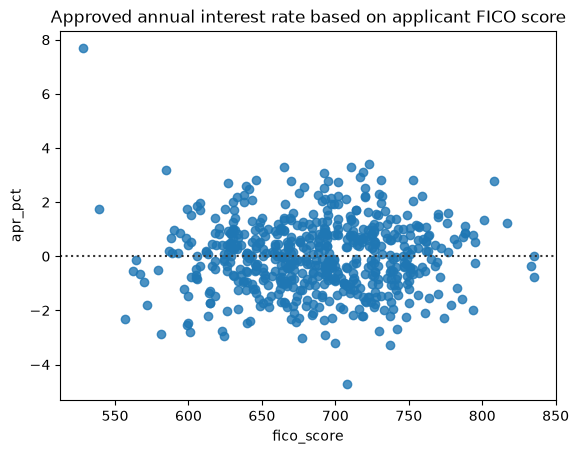

In [41]:
sns.residplot(df_clean, x = 'fico_score', y = 'apr_pct')
plt.title('Approved annual interest rate based on applicant FICO score')

## Stage 7. Diagnose influential observations

- Use an influence measure to find the most influential loan in your analysis sample.
- Show where it sits on a residual plot.
- Is there evidence that it is a data error, or does it look like a legitimate, if unusual, loan? Explain what in the data supports your answer.
- Should it stay in your analysis sample?

**Output:** a diagnostic note and a decision on the analysis sample.

In [18]:
# Given code: run this cell as it is. It needs fit from Stage 5.
# One row per loan in your model, labelled with df's row labels, with its influence measures,
# for example Cook's distance (cooks_d), hat values (hat_diag) and studentized residuals (student_resid).
# This cell shows nothing; look at measures in the next cell.
measures = fit.get_influence().summary_frame()

In [19]:
measures.head()

,dfb_Intercept,dfb_fico_score,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
0,-0.035501,0.032783,0.001262,-0.921924,0.002962,-0.050247,-0.921806,-0.050241
1,-0.007890,0.007507,0.000043,-0.132425,0.004904,-0.009296,-0.132314,-0.009288
2,0.030688,-0.034702,0.002012,-1.286413,0.002426,-0.063436,-1.287134,-0.063471
3,-0.035219,0.038959,0.001972,1.192832,0.002764,0.062795,1.193263,0.062818
4,0.004554,-0.006600,0.000400,-0.666445,0.001799,-0.028290,-0.666128,-0.028276


In [23]:
#rank by cook distance
measures.sort_values('cooks_d', ascending=False)[['cooks_d', 'hat_diag', 'student_resid']].head()

,cooks_d,hat_diag,student_resid
117,0.332187,0.018490,6.120504
119,0.026032,0.011202,2.150365
502,0.025800,0.008649,2.442292
506,0.022348,0.009200,-2.201193
40,0.021133,0.012949,-1.798342


In [39]:
#row 117 has significant cooks_d value difference

df_clean.loc[[117]]

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
117,AL100117,528.0,32016.67,21.374,C


## Stage 8. Re-estimate and compare

Whatever you decided in Stage 7, re-estimate the model without that loan.

- Store the smaller sample as `df_without_loan` and its fit as `fit_without_loan`. Leave `df` and `fit` as they are.
- Show the intercept and slope from the two fits side by side.
- Redo your Stage 6 residual plot using `df_without_loan` and `fit_without_loan`. Is a straight line still a reasonable description of how APR moves with FICO?

**Output:** a coefficient comparison and a second residual plot.

In [44]:
#store smaller sample, and show intercept and slope

df_without_loan = df_clean.drop(117)
fit_without_loan = smf.ols('apr_pct ~ fico_score', data=df_without_loan).fit()

In [43]:
# The two sets of estimates side by side
pd.DataFrame({'b': fit.params, 'se': fit.bse,
              'b_drop': fit_without_loan.params, 'se_drop': fit_without_loan.bse})

,b,se,b_drop,se_drop
Intercept,31.097860,0.732501,30.517121,0.717029
fico_score,-0.033011,0.001062,-0.032186,0.001039


Leaving row 117 out moves the coefficient on fico score from -0.033 to -0.032

Text(0.5, 1.0, 'Approved annual interest rate based on applicant FICO score')

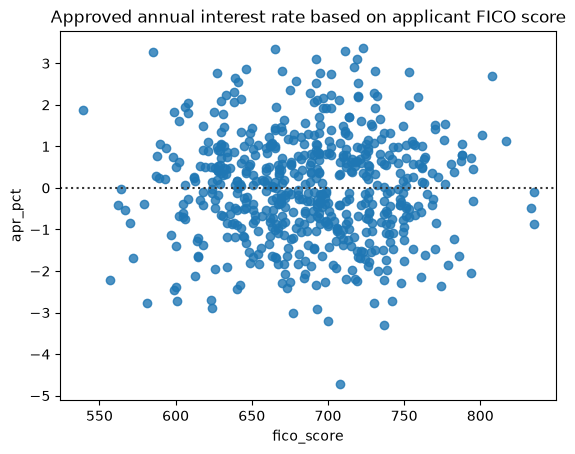

In [42]:
sns.residplot(df_without_loan, x = 'fico_score', y = 'apr_pct')
plt.title('Approved annual interest rate based on applicant FICO score')

## Stage 9. Interpret the estimate

The current rule of thumb lowers APR by 1 percentage point (a difference of -1) for every 25-point rise in FICO score. Use the fit for the sample you chose in Stage 7: `fit` if you kept the loan, `fit_without_loan` if you dropped it.

- Your slope is in percentage points of APR per FICO point. Translate it into the predicted APR difference, in percentage points, for a 25-point FICO increase.
- Do the same for the slope's 95% confidence interval.
- Using that interval, is the rule of thumb consistent with your estimate?
- What does your R-squared tell you about your model, and what does it not tell you?

**Output:** an economic interpretation.

In [48]:
fit_without_loan.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                apr_pct   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.620
Method:                 Least Squares   F-statistic:                     959.1
Date:                Tue, 13 Oct 2026   Prob (F-statistic):          2.13e-125
Time:                        14:42:17   Log-Likelihood:                -972.61
No. Observations:                 587   AIC:                             1949.
Df Residuals:                     585   BIC:                             1958.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     30.5171      0.717     42.560      0.000      29.109      31.925
fico_score    -0.0322      0.001    -30.969      0.000      -0.034      -0.030
==============================================================================
Omnibus:                        0.059   Durbin-Watson:                   2.070
Prob(Omnibus):                  0.971   Jarque-Bera (JB):                0.009
Skew:                           0.003   Prob(JB):                        0.995
Kurtosis:                       3.019   Cond. No.                     9.43e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.43e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [47]:
APR_increase = (-0.032  * 25)
APR_increase

-0.8

For every 25-point increase in FICO score, the expected value of APR decreased by 0.8 percentage points. It's lower than the rule of thumb where every 25-point increase in FICO score lowers APR by 1%.

## Stage 10. Assess causality

The slope is the causal effect of FICO only if everything else that affects APR is unrelated to FICO (zero conditional mean).

- Name two things, other than the variables in the data, that affect a quoted APR and are likely related to FICO.
- What does that mean for reading the slope as the effect of raising someone's score?

**Output:** a causal-claim verdict.

Two factors other than FICO score that may affect quoted APR and be related to FICO are:

Borrower's income: Higher-income borrowers may be considered more capable of repaying their loans and may receive lower APRs. Income may also be associated with FICO scores.

Debt-to-income ratio (DTI): Borrowers with higher DTI may be considered riskier and charged higher APRs. DTI may also be related to FICO scores.

**Causal-claim verdict:** The estimated slope cannot automatically be interpreted as the causal effect of raising someone's FICO score. If omitted factors, such as income and DTI, affect APR and are correlated with FICO, the zero conditional mean assumption may be violated. Consequently, the estimated slope may reflect both the relationship between FICO and APR and the effects of these omitted factors. Therefore, the regression establishes a negative association between FICO and APR, but does not by itself establish that increasing an individual's FICO score will causally reduce their APR.

## Stage 11. Recommendation to the head of auto-loan pricing

In one paragraph of about 150 words, cover:

- how much APR moves with FICO, with a likely range;
- whether the current rule of thumb should change;
- the limitation you think matters most;
- how the model should be used.

Write for a manager who has not taken econometrics: say what the numbers mean for pricing, in plain words.

**Output:** the recommendation.

Based on our analysis of loan applicant data, every 25-point increase in FICO score is associated with an approximately 0.8-percentage-point decrease in APR, with a likely range of 0.75–0.85 percentage points. This estimate is lower than the current rule of thumb of a 1-percentage-point decrease for every 25-point increase. Although the results suggest that the current rule may need to be reviewed, we should not replace it immediately based on this model alone. The main limitation is that the model excludes other factors that influence APR, such as borrower income, debt-to-income ratio, and loan characteristics. These factors may be related to FICO scores, meaning that the estimated relationship may not represent the actual effect of raising a borrower's score. We recommend using the model as a supporting tool for pricing decisions and preliminary estimates, alongside other borrower and loan characteristics. Before changing the pricing policy, the company should conduct further analysis to establish a more reliable causal relationship.